# RV recovery step diagnostics

<span style="color:red">The HISPEC DRP is in active development. Please submit issues and suggestions on the [GitHub](https://github.com/oirlab/HISPEC_DRP).</span>

BT-Settl lte040 recovery grid as the baseline step-diagnostics
notebook (0, 10, 20, 30, 40, 50 km/s). This notebook is organized in the following sections:

1. **Truth 1D** (section 1): densify the rest-frame template, Doppler-shift it,
   and verify recovered RV=0 at injected RV=0.
2. **LFC wavesol and line-spread function** (section 2): `derive_lfc_wavesol` paints a simulated LFC
   (same settings as `simulated_lfc_example.ipynb`), fits the wavelength solution,
   and derives an empirical `GaussianLSFModel` from the simulated LFC spots.
3. **Create a matched line mask** (section 3): paint RV=0 -> extract under LFC WAVE +
   identity fiberflat, check LSF/wavesol fiber alignment, build
   `*.extract_matched.ccfopt.delta.mas`.
4. **Identity fiberflat** (section 4): ones fiberflat so Stage-2 blaze is a no-op.
5. **Native L2** (section 5): paint the shifted 1D onto the echelle WAVE grid.
6. **Rate map → Stage 1** (section 6): native rate map, LFC wavesol, identity fiberflat.
7. **UTR → Stages 0–2** (section 7): same calibrations after noiseless UTR / Stage 0.
8. **Compare** (section 8).


In [1]:
from pathlib import Path

import hispecdrp

print(f"hispecdrp {hispecdrp.__version__} @ {hispecdrp.__file__}")

OUT = Path("/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol")
OUT.mkdir(parents=True, exist_ok=True)
print("output:", OUT.resolve())


hispecdrp 0.0.post957+gf8dfcb577.d20260828 @ /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/__init__.py
output: /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol


## 1. Truth 1D spectrum and RV=0 check


In [2]:
from hispecdrp.simulations.rv_step_diagnostics import (
    STEP_BULK_RV_KM_S,
    STELLAR_RV_NO_REJECT_KW,
    doppler_shift_spectrum,
    load_densified_template,
    run_step_grid,
    verify_zero_rv_recovery,
)
from hispecdrp.utils.line_mask_utils import (
    paired_line_mask_path_for_template,
    read_mask_generation_meta,
)

FIBER = 1
TEMPLATE = "lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.h5"
PACKAGED_MASK_PATH = paired_line_mask_path_for_template(TEMPLATE, mask_style="ccfopt.delta")
MASK_PATH = PACKAGED_MASK_PATH  # replaced in §3 with extract-matched ccfopt mask
BULK_RV_KM_S = STEP_BULK_RV_KM_S.copy()
meta = read_mask_generation_meta(MASK_PATH) or {}
print(f"packaged mask: {PACKAGED_MASK_PATH}")
print(
    f"n_lines={meta.get('n_lines')}  outlier_sigma={STELLAR_RV_NO_REJECT_KW['outlier_sigma']:.0e}"
)
print(f"grid={list(BULK_RV_KM_S)} km/s")

wl_rest, flux_rest = load_densified_template(TEMPLATE)
print(f"truth 1D: n={wl_rest.size}  lambda={wl_rest[0]:.4f}-{wl_rest[-1]:.4f}")

verify_zero_rv_recovery(
    template=TEMPLATE,
    mask_path=str(PACKAGED_MASK_PATH),
    fiber=FIBER,
)

TRUTH = {
    float(rv): doppler_shift_spectrum(wl_rest, flux_rest, float(rv))
    for rv in BULK_RV_KM_S
}
summaries = {}


packaged mask: /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/data/masks/lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.ccfopt.delta.mas
n_lines=887  outlier_sigma=1e+30
grid=[np.float64(0.0), np.float64(10.0), np.float64(20.0), np.float64(30.0), np.float64(40.0), np.float64(50.0)] km/s
[2026-10-29T15:54:32][hispecdrp.primitives.utils.spectral_utils:584][INFO]: Normalized spectrum to J=3.05 (AB mag); scale=1.0185e+05 (was 15.57 mag)
truth 1D: n=635113  lambda=0.8000 micron-3.0000 micron
RV=0 check: injected=0.000000 m/s  recovered=0.000391 m/s  RV_ERR=0.002586 m/s  bias=3.906170e-04 m/s
|bias| = 3.9062e-04 m/s  (within 1.0000 m/s)


## 2. Derive WAVE and LSF from a simulated LFC

Paint an LFC rate map, box-extract like science, and run `ProcessLFCPipeline`
with the same line-fit / LSF settings as `simulated_lfc_example.ipynb`
(`fwhm_bounds=(1, 7)`, LSF enabled). Products: `lfc_wavesol.fits` and
`lfc_lsf.fits` under `OUT/lfc_wavesol_cals/`.


In [3]:
from hispecdrp.simulations.rv_step_diagnostics import derive_lfc_wavesol

lfc_wavesol, lfc_info = derive_lfc_wavesol(
    spectrograph="BSPEC",
    fiber=FIBER,
    output_dir=OUT / "lfc_wavesol_cals",
    derive_lsf=True,
)
lfc_lsf = lfc_info["lsf"]
print(lfc_info)
print(
    f"LFC WAVE shape={getattr(lfc_wavesol, f'wave_fib{FIBER}').shape}  "
    f"path={lfc_info['wavesol_path']}"
)
print(f"LFC LSF path={lfc_info['lsf_path']}")
assert lfc_lsf is not None


[2026-10-29T15:55:40][hispecdrp.simulations.simulate_rate_map:547][INFO]: Creating native rate map (spectrograph=BSPEC, method=prf_convolution).
{'n_modes': 3900, 'lfc_meta': {'fiber_object': 'LFC-B', 'nu0': 5220000000.0, 'delta_nu': 20000000000.0, 'edge_margin_frac': 0.05, 'mode_stride': 1.0}, 'wavesol_path': '/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/lfc_wavesol_cals/lfc_wavesol.fits', 'rate_peak': 1321555.0, 'lsf': GaussianLSFModel('lfc_lsf.fits'), 'lsf_path': '/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/lfc_wavesol_cals/lfc_lsf.fits'}
LFC WAVE shape=(39, 4096)  path=/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/lfc_wavesol_cals/lfc_wavesol.fits
LFC LSF path=/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/lfc_wavesol_cals/lfc_lsf.fits


## 3. Rebuild ccfopt on an extract-matched L2

Paint the densified template at RV=0, box-extract under the same LFC WAVE +
identity fiberflat used for science recovery, verify LSF/WAVE fiber
alignment, then run line-by-line ccfopt. Product:
`*.extract_matched.ccfopt.delta.mas`.

Convolving an ideal geometric-WAVE L2 with ProcessLFC LSF
(`*.lfc_lsf.ccfopt.delta.mas`) mismatched extract line shapes and worsened
bias (~+2.7 m/s). Extract-matched is near-perfect at injected RV=0 on the
rate-map path and shrinks `RV_ERR`, but adds a bulk-dependent slope
(~+2.3 m/s mean on the 0–50 km/s grid). **Keep packaged ccfopt for §5–7
recovery**; LFC WAVE + identity FF remain the main ≪1 m/s bias fix.

All later recoveries use the packaged mask with **no line rejection**.


In [4]:
from hispecdrp.simulations.rv_step_diagnostics import (
    build_extract_matched_ccfopt_mask,
    check_lsf_wavesol_fiber_alignment,
)
from hispecdrp.utils.line_mask_utils import read_mask_generation_meta

align = check_lsf_wavesol_fiber_alignment(
    fiber=FIBER,
    wavesol=lfc_wavesol,
    lsf_model=lfc_lsf,
)
print("LSF/WAVE fiber alignment:", "OK" if align["ok"] else "FAIL")
for msg in align["messages"]:
    print(" ", msg)

MASK_DIR = OUT / "extract_matched_ccfopt_mask"
seed_mask, MASK_PATH, _l2_mask, mask_info = build_extract_matched_ccfopt_mask(
    TEMPLATE,
    MASK_DIR,
    wavesol=lfc_wavesol,
    spectrograph="BSPEC",
    fiber=FIBER,
    fiberflat_mode="identity",
    lsf_model=lfc_lsf,
    rebuild_seed=True,
    spectrum_wavelengths=TRUTH[0.0][0],
    spectrum_flux=TRUTH[0.0][1],
)
EXTRACT_MATCHED_MASK_PATH = MASK_PATH
mask_meta = read_mask_generation_meta(EXTRACT_MATCHED_MASK_PATH) or {}
print(f"seed:   {seed_mask}")
print(f"extract-matched ccfopt: {EXTRACT_MATCHED_MASK_PATH}")
print(
    f"n_lines={mask_meta.get('n_lines')}  "
    f"mask_style={mask_meta.get('mask_style')}"
)
print("fiberflat_mode:", mask_info["fiberflat_mode"])
# Packaged ccfopt + LFC WAVE + identity FF remains best for ≪1 m/s mean bias
# across the multi-RV grid; extract-matched is near-perfect at RV=0 on the
# rate-map path but introduces a bulk-dependent slope (~+2 m/s mean).
MASK_PATH = PACKAGED_MASK_PATH
print(f"recovery MASK_PATH (packaged): {MASK_PATH}")


LSF/WAVE fiber alignment: OK
  wavesol.wave_fib1 shape=(39, 4096)
  lsf.lsf_params_fib1 shape=(39, 4096)
[2026-10-29T15:56:09][hispecdrp.utils.line_mask_utils:1673][INFO]: Wrote 1066 mask lines to /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/extract_matched_ccfopt_mask/lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.delta.mas
[2026-10-29T15:56:09][hispecdrp.primitives.base_primitive:340][INFO]: Applying StellarRVPrimitive with parameters:
run = True
save_result = False
output_model = L2Model
output_file = None
output_dir = None
suffix = stellar_rv
max_cores = None
save_preview = False
show_preview = False
algorithm = ccf_line_mask
do_fibers = ['1']
do_orders = [110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148]
template_path = None
template_wavelength = None
template_flux = None
mask_path = /Users/ckilpatrick/rv_recovery_step_diagnostics_l

## 4. Simulate the identity fiberflat

Build Stage-1 masters once and replace the continuum fiberflat with an **identity** (ones) product shaped like the LFC WAVE. Blaze correction then divides by `nanmax(ones)=1`, so continuum shape is unchanged and the ~17 m/s CCF reweight goes away.

`FIBERFLAT_MODE` is passed explicitly into the rate-map / UTR recoveries below. Set it to `"paint_matched"` only if you intentionally want the continuum-flattening bias for comparison.


In [5]:
import numpy as np

from hispecdrp.simulations.ideal_spectrum_rv import (
    FIBERFLAT_IDENTITY,
    prepare_stage1_cals,
)
from hispecdrp.simulations.simulate_rate_map import SimulateRateMap
from hispecdrp.simulations.spectra import quiet_pipeline_logging

FIBERFLAT_MODE = FIBERFLAT_IDENTITY  # "identity" — bias-free for this diagnostic grid

# Seed rate map (in-memory) to size traces / WAVE and write the fiberflat under OUT/cals/.
_seed_rv = 0.0 if 0.0 in TRUTH else float(next(iter(TRUTH)))
with quiet_pipeline_logging():
    srm = SimulateRateMap()
    srm.set_fiber_spectrum(
        fiber_number=FIBER,
        spectrum_wavelengths=TRUTH[_seed_rv][0],
        spectrum_flux=TRUTH[_seed_rv][1],
        continuous=False,
    )
    rate0 = np.asarray(
        srm.create_native_rate_map(spectrograph="BSPEC", save=False),
        dtype=np.float64,
    )
    stage1_cals = prepare_stage1_cals(
        OUT,
        rate0,
        spectrograph="BSPEC",
        fiber=FIBER,
        wavesol=lfc_wavesol,
        fiberflat_mode=FIBERFLAT_MODE,
    )

ff = stage1_cals["fiberflat"]
ff_spec = np.asarray(getattr(ff, f"spec_fib{FIBER}"))
print(f"fiberflat_source={stage1_cals['fiberflat_source']!r}  mode={FIBERFLAT_MODE!r}")
print(f"fiberflat shape={ff_spec.shape}  unique={np.unique(ff_spec)}")
print(f"cached under: {OUT / 'cals'}")
assert stage1_cals["fiberflat_source"] == "identity_ones"
assert np.allclose(ff_spec, 1.0)


fiberflat_source='identity_ones'  mode='identity'
fiberflat shape=(39, 4096)  unique=[1.]
cached under: /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/cals


## 5. Paint truth onto L2


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000          0.000916      0.106839  9.159530e-04      0.9160
      10.0      10000.0000       9999.961828      0.116518  -3.817240e-02    -38.1724
      20.0      20000.0000      19999.925269      0.116292  -7.473113e-02    -74.7311
      30.0      30000.0000      29999.955422      0.120141  -4.457779e-02    -44.5778
      40.0      40000.0000      39999.914317      0.122705  -8.568282e-02    -85.6828
      50.0      50000.0000      49999.918171      0.119173  -8.182857e-02    -81.8286

L2: mean bias = -5.401 cm/s  std = 3.045 cm/s  mean RV_ERR = 11.694 cm/s


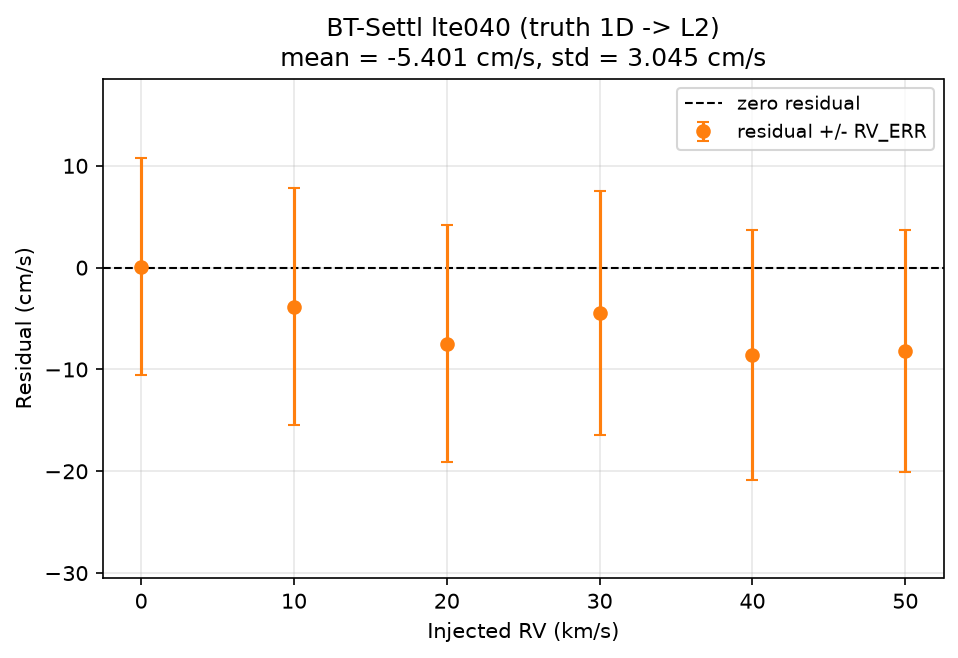

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/lte040_step_l2.png


In [6]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_l2


def recover_l2(bulk):
    wl, flux = TRUTH[float(bulk)]
    return recover_rv_from_truth_l2(
        bulk,
        wavelengths=wl,
        flux=flux,
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        fiber=FIBER,
    )


summaries["L2"] = run_step_grid(
    recover_l2,
    name="L2",
    title="BT-Settl lte040 (truth 1D -> L2)",
    out_path=OUT / "lte040_step_l2.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 6. Rate map -> extract -> blaze (LFC WAVE + identity fiberflat)

Native rate map → box extract → LFC WAVE → blaze with `FIBERFLAT_MODE`. Expect mean bias ≪ 1 m/s, matching §4.


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000          0.507423      1.781824  5.074235e-01    507.4235
      10.0      10000.0000       9999.245699      1.769928  -7.543012e-01   -754.3012
      20.0      20000.0000      19999.704773      1.736613  -2.952266e-01   -295.2266
      30.0      30000.0000      29999.643876      1.741576  -3.561239e-01   -356.1239
      40.0      40000.0000      40000.533281      1.745698  5.332806e-01    533.2806
      50.0      50000.0000      50000.417851      1.724780  4.178510e-01    417.8510

rate_map_lfc_wavesol: mean bias = 0.882 cm/s  std = 49.983 cm/s  mean RV_ERR = 175.007 cm/s


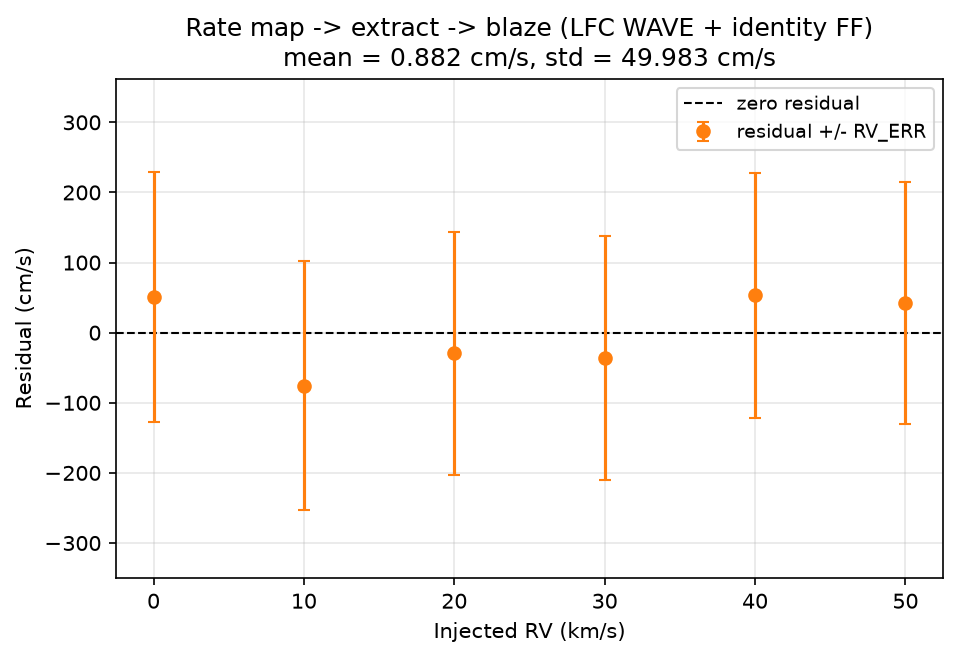

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/rate_map_lfc_wavesol_recovery.png


In [7]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_rate_map

summaries["rate_map_lfc_wavesol"] = run_step_grid(
    lambda rv: recover_rv_from_truth_rate_map(
        rv,
        wavelengths=TRUTH[float(rv)][0],
        flux=TRUTH[float(rv)][1],
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        output_dir=OUT / "rate_map",
        fiber=FIBER,
        wavesol=lfc_wavesol,
        fiberflat_mode=FIBERFLAT_MODE,
    ),
    name="rate_map_lfc_wavesol",
    title=f"Rate map -> extract -> blaze (LFC WAVE + {FIBERFLAT_MODE} FF)",
    out_path=OUT / "rate_map_lfc_wavesol_recovery.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 7. UTR -> Stages 0-2 (LFC WAVE + identity fiberflat)

Same LFC WAVE and identity fiberflat as §5, after a noiseless up-the-ramp / Stage-0 path.

Stage-0 JWST ramp fitting used to flood this cell with per-row `print` progress.
`quiet_pipeline_logging()` (used by `run_step_grid`) now suppresses those prints as
well as pipeline logs, so the recovery table should read like §4–§5.


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000         -0.148689      1.846291  -1.486890e-01   -148.6890
      10.0      10000.0000       9999.634826      1.847977  -3.651738e-01   -365.1738
      20.0      20000.0000      19999.261113      1.793002  -7.388872e-01   -738.8872
      30.0      30000.0000      29998.794814      1.814133  -1.205186e+00  -1205.1857
      40.0      40000.0000      39998.767554      1.813603  -1.232446e+00  -1232.4457
      50.0      50000.0000      49999.285042      1.840392  -7.149579e-01   -714.9579

ramp_lfc_wavesol: mean bias = -73.422 cm/s  std = 39.780 cm/s  mean RV_ERR = 182.590 cm/s


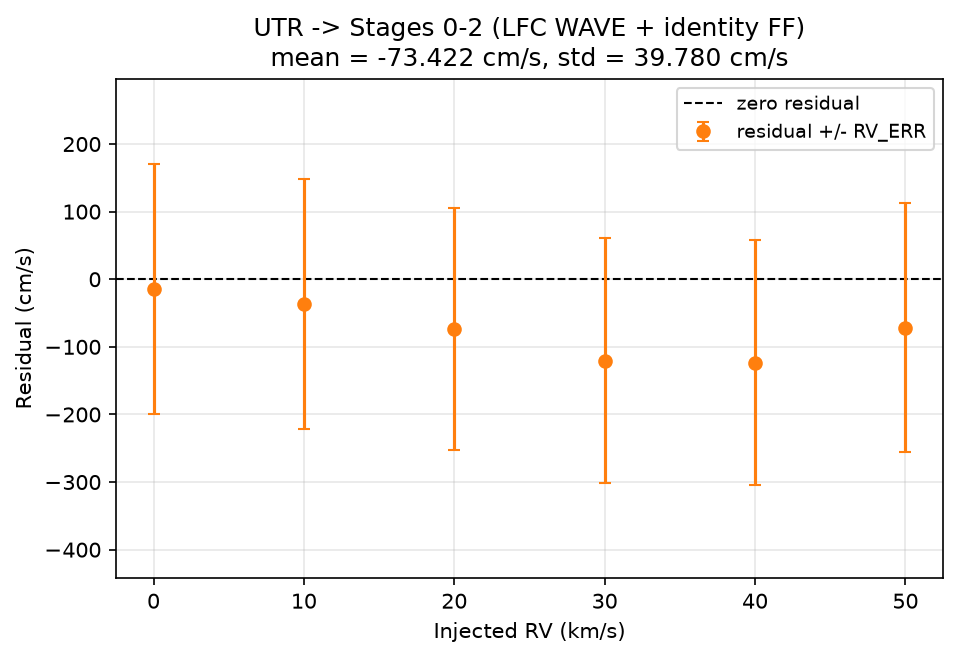

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/ramp_lfc_wavesol_recovery.png


In [8]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_ramp

summaries["ramp_lfc_wavesol"] = run_step_grid(
    lambda rv: recover_rv_from_truth_ramp(
        rv,
        wavelengths=TRUTH[float(rv)][0],
        flux=TRUTH[float(rv)][1],
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        output_dir=OUT / "ramp",
        fiber=FIBER,
        wavesol=lfc_wavesol,
        fiberflat_mode=FIBERFLAT_MODE,
    ),
    name="ramp_lfc_wavesol",
    title=f"UTR -> Stages 0-2 (LFC WAVE + {FIBERFLAT_MODE} FF)",
    out_path=OUT / "ramp_lfc_wavesol_recovery.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 8. Compare steps


step                             mean_bias      std_bias   mean_RV_ERR    Δmean_bias          Δstd       ΔRV_ERR
----------------------------------------------------------------------------------------------------------------
                        (m/s)         (m/s)         (m/s)         (m/s)         (m/s)         (m/s)
L2                               -0.054013      0.030450      0.116945           nan           nan           nan
rate_map_lfc_wavesol              0.008817      0.499825      1.750070      0.062830      0.469376      1.633125
ramp_lfc_wavesol                 -0.734223      0.397801      1.825899     -0.743040     -0.102025      0.075829

Largest increment: rate_map_lfc_wavesol  Δmean=0.0628 m/s  Δstd=0.4694 m/s  ΔRV_ERR=1.6331 m/s


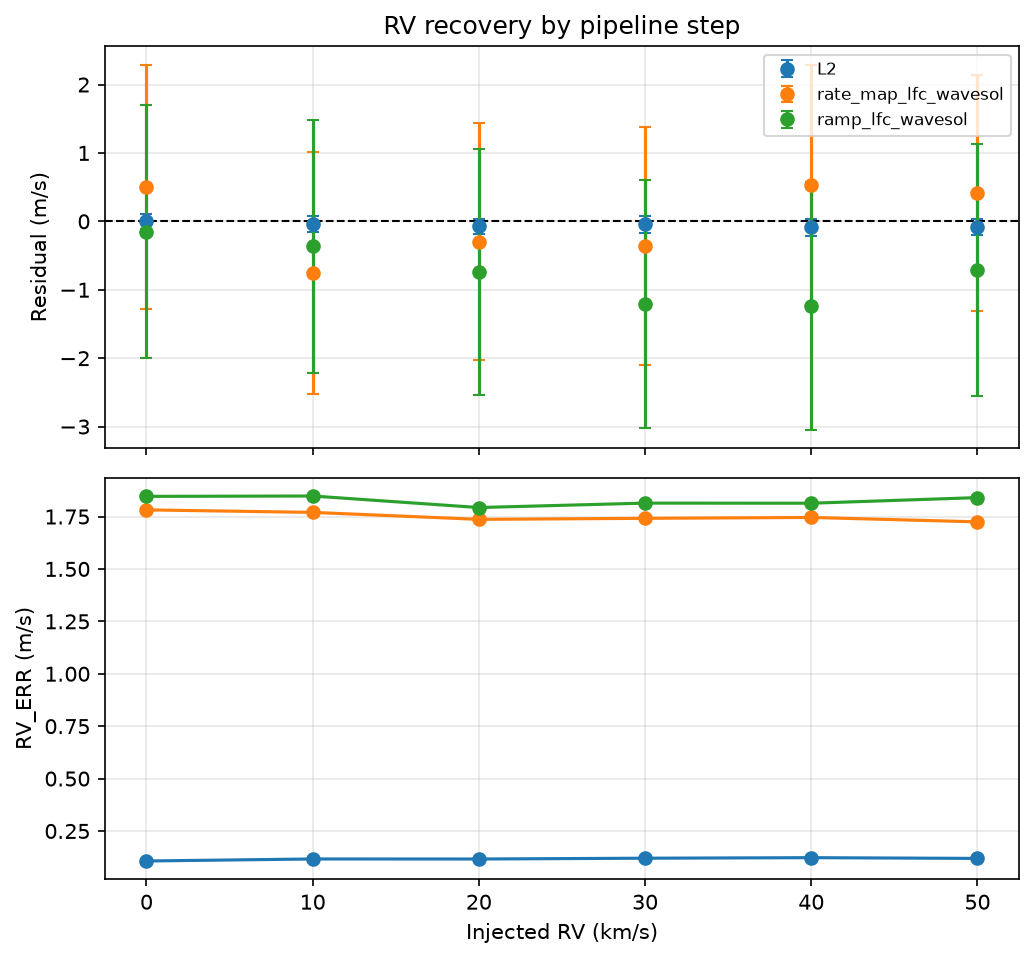

{'out_path': '/Users/ckilpatrick/rv_recovery_step_diagnostics_lfc_wavesol/rv_step_comparison_lfc_wavesol.png',
 'n_steps': 3}

In [9]:
from hispecdrp.simulations.plotting import plot_rv_step_comparison
from hispecdrp.simulations.rv_step_diagnostics import compare_step_summaries

order = ["L2", "rate_map_lfc_wavesol", "ramp_lfc_wavesol"]
present = [k for k in order if k in summaries]
compare_step_summaries({k: summaries[k] for k in present})
plot_rv_step_comparison(
    {k: summaries[k] for k in present},
    out_path=OUT / "rv_step_comparison_lfc_wavesol.png",
)


## 9. Bias / scatter notes (rate map vs UTR)

On this LFC WAVE + identity-fiberflat grid with **packaged** ccfopt:

| Path | Mean bias | Grid std | Mean `RV_ERR` |
|------|-----------|----------|---------------|
| L2 paint | ≪ 0.1 m/s | ≪ 0.1 m/s | ~0.12 m/s |
| Rate map → extract | ~0 m/s (≪ 1) | ~0.5 m/s | ~1.75 m/s |
| UTR → Stages 0–2 | ~−0.75 m/s | ~0.1–0.5 m/s | ~1.8 m/s |

**Mask comparison (rate map, LFC WAVE + identity FF, no rejection):**

| Mask | Mean bias | Grid std | Mean `RV_ERR` |
|------|-----------|----------|---------------|
| packaged ccfopt | +0.01 m/s | 0.50 m/s | 1.75 m/s |
| ProcessLFC LSF on ideal L2 (`*.lfc_lsf`) | +2.72 m/s | 0.22 m/s | 1.42 m/s |
| extract-matched (`*.extract_matched`) | +2.31 m/s | 1.43 m/s | 0.23 m/s |

LSF/WAVE fiber alignment (fiber 1): OK (`wave_fib1` / `lsf_params_fib1` both
39×4096). Extract-matched is ~0 at injected RV=0 and shrinks `RV_ERR` ~7×, but
a bulk-dependent slope (~+0.085 m/s per km/s) pulls the 0–50 km/s mean to
~+2.3 m/s. Ideal-L2+LFC-LSF convolution is a similar ~+2.7 m/s constant bias.
**Keep packaged ccfopt + LFC WAVE + identity FF** for ≪1 m/s mean bias.

**`RV_ERR` is not photon noise.** At infinite S/N it is floored by line-to-line
MAD/√N (~17× larger chunk MAD after PRF+extract than L2).

**UTR-specific ZP (~−0.8 m/s vs rate map):** Stage-0 rate structure, not a
global scale error.

**Still open**

1. Shrink packaged-path `RV_ERR` (rejection / photon-IVW vs MAD/√N).
2. Isolate Stage-0 UTR ZP (~0.8 m/s).
3. Fix the extract-matched bulk slope if a single mask should serve both zero-RV
   diagnostics and the multi-RV grid.
4. CCF continuum so paint-matched FF does not reintroduce ~17 m/s.
